# Design of FIR Filters (Window Method)

N = 31, Sampling frequency = 10 kHz, Enrollment No: 92400133081

In [1]:
# write a python program to design FIR low pass, high pass, band pass and band stop filters

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

N = 31          # number of filter coefficients (taps)
fs = 10000      # sampling frequency in Hz

# Function to display the frequency response of a filter
def plot_response(h, fs, title):
    w, H = freqz(h, worN=1024, fs=fs)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(w, abs(H))
    plt.title(title)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(w, 20 * np.log10(abs(H) + 1e-10))
    plt.title('Magnitude in dB')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude (dB)')
    plt.ylim(-100, 5)
    plt.grid(True)

    plt.tight_layout()
    plt.show()

## 1. FIR Low pass filter (cutoff = 3 kHz, N = 31, fs = 10 kHz)

Filter coefficients:
[ 0.      0.0019 -0.0017 -0.0026  0.0064 -0.     -0.0134  0.0115  0.0157
 -0.0344  0.      0.0641 -0.0568 -0.0897  0.2994  0.5993  0.2994 -0.0897
 -0.0568  0.0641  0.     -0.0344  0.0157  0.0115 -0.0134 -0.      0.0064
 -0.0026 -0.0017  0.0019  0.    ]


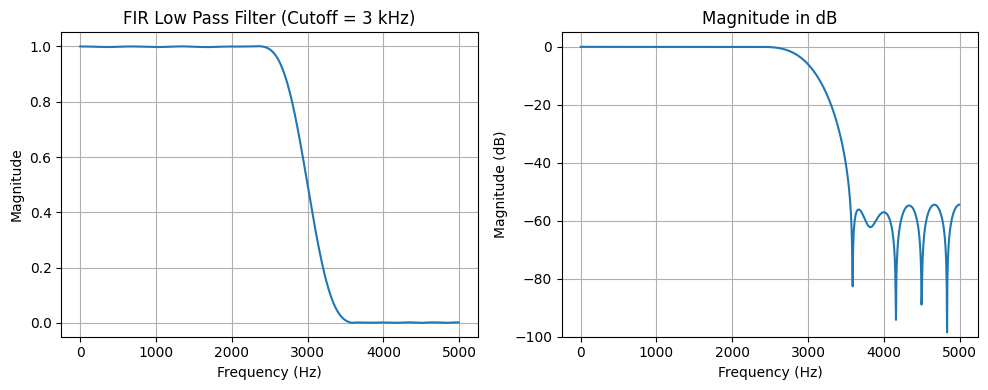

In [2]:
cutoff = 3000
h_lp = firwin(N, cutoff, fs=fs)      # hamming window is used by default

print("Filter coefficients:")
print(np.round(h_lp, 4))

plot_response(h_lp, fs, 'FIR Low Pass Filter (Cutoff = 3 kHz)')

## 2. FIR High pass filter (cutoff = 3 kHz, N = 31, fs = 10 kHz)

Filter coefficients:
[ 0.     -0.002   0.0017  0.0026 -0.0064 -0.      0.0134 -0.0115 -0.0157
  0.0345  0.     -0.0643  0.057   0.09   -0.3003  0.4008 -0.3003  0.09
  0.057  -0.0643  0.      0.0345 -0.0157 -0.0115  0.0134 -0.     -0.0064
  0.0026  0.0017 -0.002   0.    ]


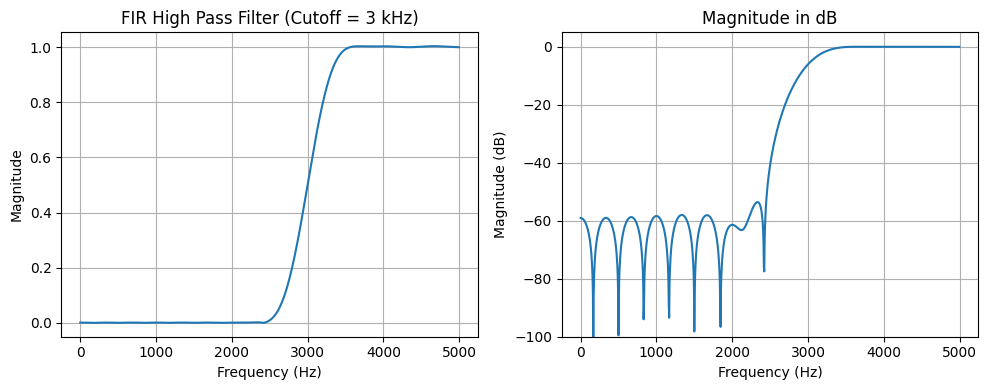

In [3]:
cutoff = 3000
h_hp = firwin(N, cutoff, pass_zero=False, fs=fs)

print("Filter coefficients:")
print(np.round(h_hp, 4))

plot_response(h_hp, fs, 'FIR High Pass Filter (Cutoff = 3 kHz)')

## 3. FIR Band pass filter (cutoff = 3 kHz, 6 kHz, N = 31, fs = 10 kHz)

With fs = 10 kHz the Nyquist frequency is fs/2 = 5 kHz, so the upper cutoff of 6 kHz is not possible. The band 3 kHz - 6 kHz is limited to 3 kHz - 5 kHz, which makes the filter work as a high pass filter. A second design with fs = 20 kHz (Nyquist = 10 kHz) is given to show the real band pass filter.

Filter coefficients (fs = 10 kHz):
[ 0.     -0.002   0.0017  0.0026 -0.0064 -0.      0.0134 -0.0115 -0.0157
  0.0345  0.     -0.0643  0.057   0.09   -0.3003  0.4008 -0.3003  0.09
  0.057  -0.0643  0.      0.0345 -0.0157 -0.0115  0.0134 -0.     -0.0064
  0.0026  0.0017 -0.002   0.    ]


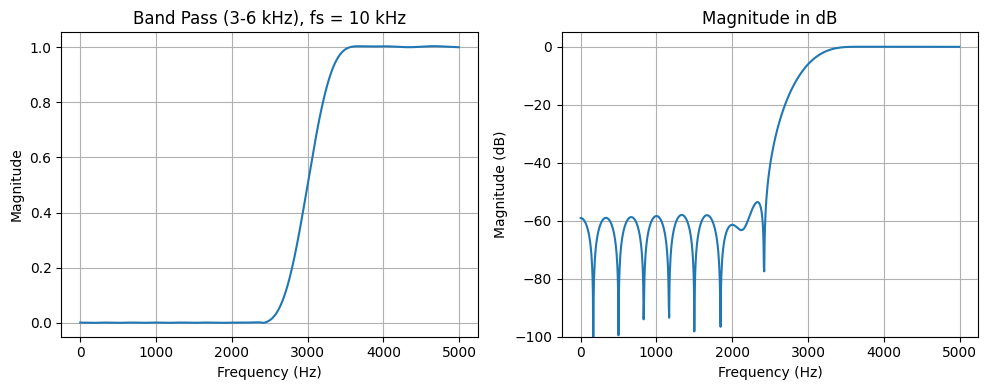

In [4]:
# fs = 10 kHz : upper cutoff 6 kHz is above Nyquist (5 kHz), so only 3 kHz is used
h_bp1 = firwin(N, 3000, pass_zero=False, fs=fs)

print("Filter coefficients (fs = 10 kHz):")
print(np.round(h_bp1, 4))

plot_response(h_bp1, fs, 'Band Pass (3-6 kHz), fs = 10 kHz')

Filter coefficients (fs = 20 kHz):
[-0.0017  0.0007 -0.0008  0.0016  0.0118 -0.     -0.0247 -0.0071  0.0074
 -0.0131  0.0488  0.1034 -0.0865 -0.2343  0.0446  0.2989  0.0446 -0.2343
 -0.0865  0.1034  0.0488 -0.0131  0.0074 -0.0071 -0.0247 -0.      0.0118
  0.0016 -0.0008  0.0007 -0.0017]


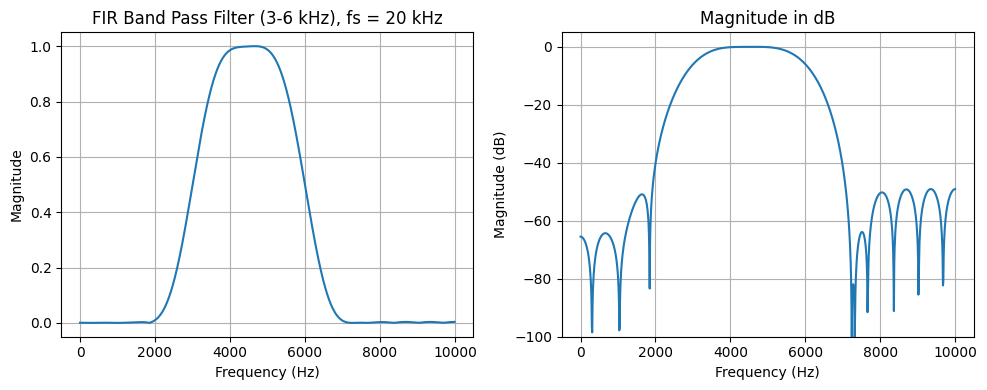

In [5]:
# fs = 20 kHz : both cutoffs 3 kHz and 6 kHz are valid
fs2 = 20000
h_bp2 = firwin(N, [3000, 6000], pass_zero=False, fs=fs2)

print("Filter coefficients (fs = 20 kHz):")
print(np.round(h_bp2, 4))

plot_response(h_bp2, fs2, 'FIR Band Pass Filter (3-6 kHz), fs = 20 kHz')

## 4. FIR Band stop filter (cutoff = 3 kHz, 6 kHz, N = 31, fs = 10 kHz)

For the same reason, with fs = 10 kHz the stop band 3 kHz - 6 kHz is limited to 3 kHz - 5 kHz, which makes the filter work as a low pass filter. The real band stop filter is designed with fs = 20 kHz.

Filter coefficients (fs = 10 kHz):
[ 0.      0.0019 -0.0017 -0.0026  0.0064 -0.     -0.0134  0.0115  0.0157
 -0.0344  0.      0.0641 -0.0568 -0.0897  0.2994  0.5993  0.2994 -0.0897
 -0.0568  0.0641  0.     -0.0344  0.0157  0.0115 -0.0134 -0.      0.0064
 -0.0026 -0.0017  0.0019  0.    ]


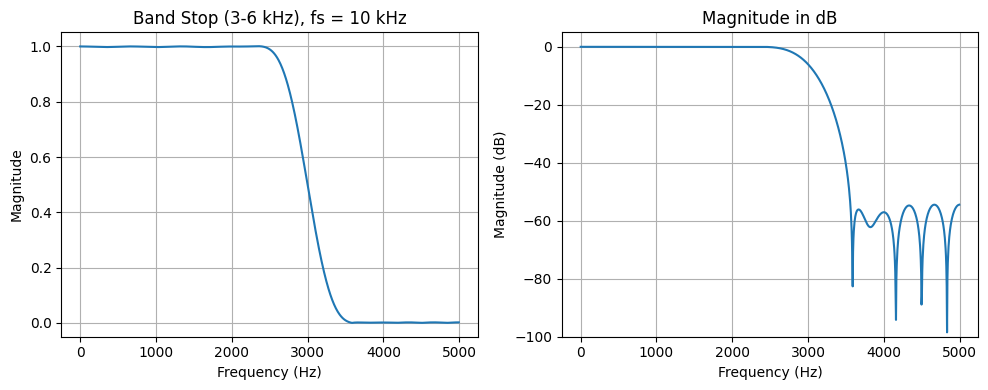

In [6]:
# fs = 10 kHz : upper cutoff 6 kHz is above Nyquist (5 kHz), so only 3 kHz is used
h_bs1 = firwin(N, 3000, fs=fs)

print("Filter coefficients (fs = 10 kHz):")
print(np.round(h_bs1, 4))

plot_response(h_bs1, fs, 'Band Stop (3-6 kHz), fs = 10 kHz')

Filter coefficients (fs = 20 kHz):
[ 0.0017 -0.0007  0.0008 -0.0016 -0.0118 -0.      0.0248  0.0071 -0.0075
  0.0131 -0.049  -0.1038  0.0867  0.235  -0.0447  0.6996 -0.0447  0.235
  0.0867 -0.1038 -0.049   0.0131 -0.0075  0.0071  0.0248 -0.     -0.0118
 -0.0016  0.0008 -0.0007  0.0017]


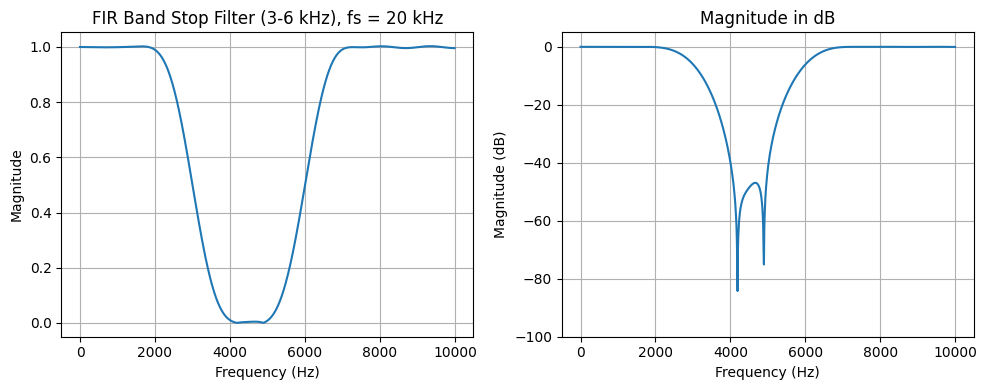

In [7]:
# fs = 20 kHz : both cutoffs 3 kHz and 6 kHz are valid
fs2 = 20000
h_bs2 = firwin(N, [3000, 6000], fs=fs2)      # pass_zero=True gives band stop

print("Filter coefficients (fs = 20 kHz):")
print(np.round(h_bs2, 4))

plot_response(h_bs2, fs2, 'FIR Band Stop Filter (3-6 kHz), fs = 20 kHz')